In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from src.config import load_yaml_config
from src.data import load_data_from_json, check_hourly_continuity
from src.cleaning import clean_dataset
from src.preprocessing import add_rain_event, prepare_city_stream
from src.results import ExperimentResults
from src.latex import print_latex_results_tables


def get_fresh_dataframes_and_config() -> tuple[dict, pd.DataFrame, pd.DataFrame]:
    """Loads a fresh config and fresh, cleaned dataframes for both cities in order to avoid issues with notebook usage."""
    # Load the config
    config = load_yaml_config()
    
    # Load the datasets
    df_raw_lisboa = load_data_from_json(config["data"], "Lisboa")
    df_raw_porto = load_data_from_json(config["data"], "Porto")
    
    # Clean the datasets
    df_cleaned_lisboa = clean_dataset(config["cleaning"], df_raw_lisboa)
    df_cleaned_porto = clean_dataset(config["cleaning"], df_raw_porto)
    
    # Add the rain event columns
    add_rain_event(df_cleaned_lisboa)
    add_rain_event(df_cleaned_porto)

    return config, df_cleaned_lisboa, df_cleaned_porto

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Exploratory Data Analysis

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

config, df_lisboa, df_porto = get_fresh_dataframes_and_config()

## City A: Lisboa

In [6]:
display(df_lisboa)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rain_event
0,2020-01-01 00:00:00,8.6,95.0,0.0,6.7,0
1,2020-01-01 01:00:00,10.0,92.0,0.0,7.7,0
2,2020-01-01 02:00:00,9.2,94.0,0.0,7.4,0
3,2020-01-01 03:00:00,9.2,94.0,0.0,8.1,0
4,2020-01-01 04:00:00,9.0,95.0,0.0,8.9,0
...,...,...,...,...,...,...
52603,2025-12-31 19:00:00,10.4,86.0,0.0,6.1,0
52604,2025-12-31 20:00:00,10.4,87.0,0.0,5.7,0
52605,2025-12-31 21:00:00,10.6,87.0,0.0,5.5,0
52606,2025-12-31 22:00:00,10.5,89.0,0.0,9.0,0


In [7]:
df_lisboa.info()

<class 'pandas.DataFrame'>
RangeIndex: 52608 entries, 0 to 52607
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  52608 non-null  datetime64[us]
 1   temperature_2m        52608 non-null  float64       
 2   relative_humidity_2m  52608 non-null  float64       
 3   precipitation         52608 non-null  float64       
 4   wind_speed_10m        52608 non-null  float64       
 5   rain_event            52608 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 2.4 MB


In [8]:
# Check the percentage of missing values for each column:
round(df_lisboa.isna().sum() / len(df_lisboa) * 100, 2)

time                    0.0
temperature_2m          0.0
relative_humidity_2m    0.0
precipitation           0.0
wind_speed_10m          0.0
rain_event              0.0
dtype: float64

In [9]:
df_lisboa.duplicated().sum()

np.int64(0)

In [10]:
# Class distribution
df_lisboa["rain_event"].value_counts(normalize=True)

rain_event
0    0.879334
1    0.120666
Name: proportion, dtype: float64

Add the $C^{(24)}_t$ feature:

In [17]:
df_lisboa["rainy_hours_previous_24h"] = df_lisboa["rain_event"].shift(1).rolling(24).sum()

In [18]:
# Descriptive statistics
df_lisboa.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rain_event,rainy_hours_previous_24h
count,52608,52608.000000,52608.000000,52608.000000,52608.000000,52608.000000,52584.000000
mean,2022-12-31 23:30:00,17.275540,74.434877,0.074584,12.731623,0.120666,2.897307
min,2020-01-01 00:00:00,1.500000,14.000000,0.000000,0.000000,0.000000,0.000000
25%,2021-07-01 23:45:00,13.600000,63.000000,0.000000,7.800000,0.000000,0.000000
50%,2022-12-31 23:30:00,16.900000,78.000000,0.000000,12.000000,0.000000,0.000000
75%,2024-07-01 23:15:00,20.200000,89.000000,0.000000,16.700000,0.000000,4.000000
90%,2025-05-26 18:18:00,24.500000,94.000000,0.100000,21.500000,1.000000,10.000000
95%,2025-09-13 08:39:00,27.000000,96.000000,0.300000,24.400000,1.000000,15.000000
99%,2025-12-10 00:55:48,31.800000,99.000000,1.900000,30.200000,1.000000,21.000000
max,2025-12-31 23:00:00,40.700000,100.000000,19.200000,48.800000,1.000000,24.000000


In [12]:
check_hourly_continuity(df_lisboa)

Number of observations: 52608
Duplicate timestamps: 0
Non-hourly transitions: 0
The stream is continuous at hourly intervals.


Series([], Name: time, dtype: timedelta64[us])

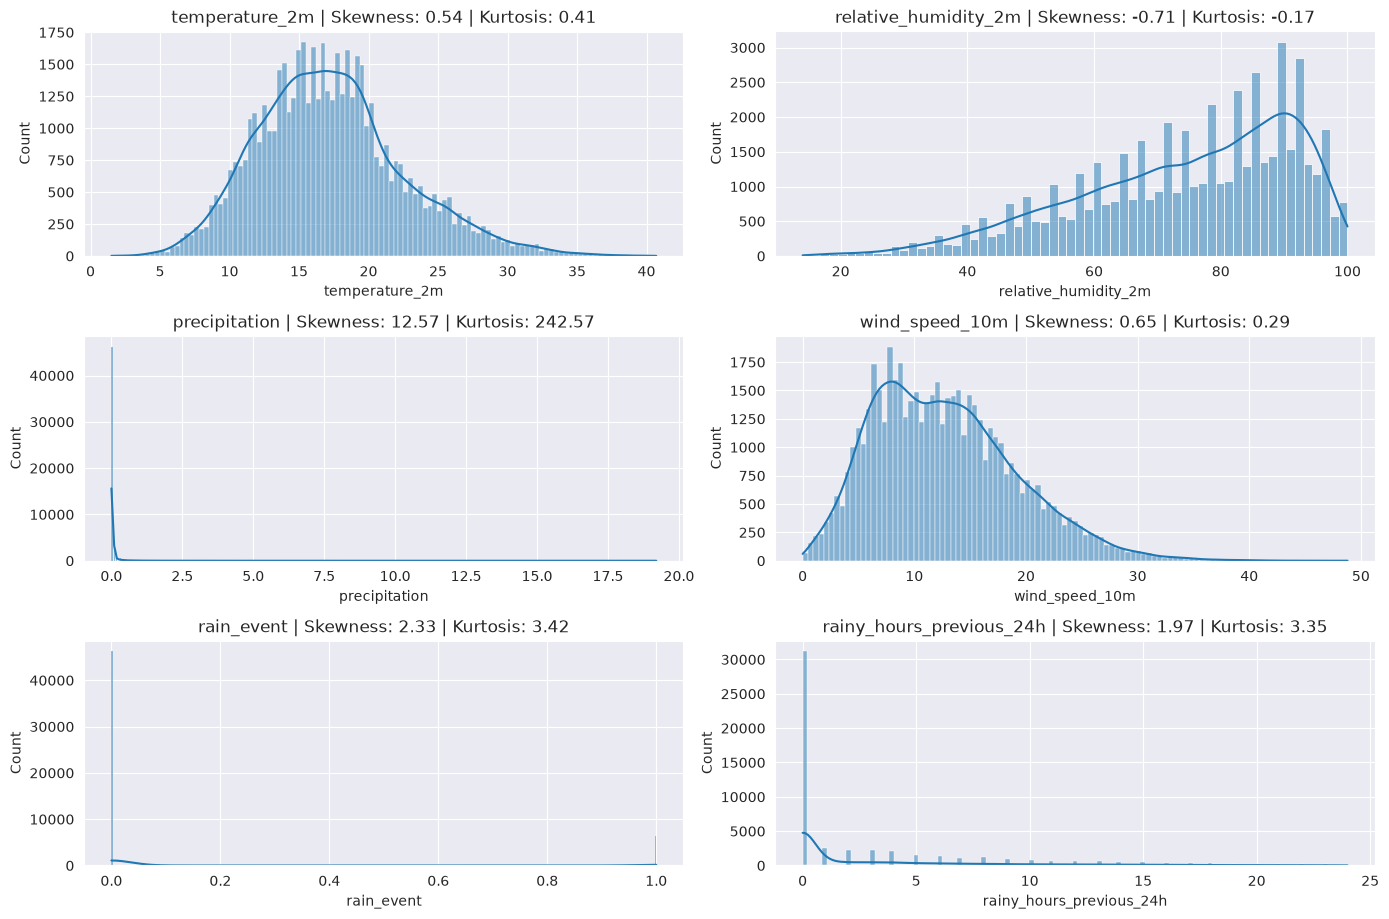

In [19]:
# Plot the weather variables distribution

numerical_columns = df_lisboa.select_dtypes(include=["int64", "float64"]).columns

plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 2, idx)
    sns.histplot(df_lisboa[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df_lisboa[feature].skew(), 2)} | Kurtosis: {round(df_lisboa[feature].kurtosis(), 2)}")

plt.tight_layout()
plt.show()

Calculate $\Pr(H_t \geq 50\% \mid y_t=1)$:

In [14]:
rainy = df_lisboa[df_lisboa["rain_event"] == 1]
print((rainy["relative_humidity_2m"] >= 50).mean())

0.998109640831758


## City B: Porto

In [5]:
display(df_porto)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rain_event
0,2020-01-01 00:00:00,5.4,99.0,0.0,6.2,0
1,2020-01-01 01:00:00,5.7,99.0,0.0,8.9,0
2,2020-01-01 02:00:00,5.5,98.0,0.0,10.0,0
3,2020-01-01 03:00:00,5.5,95.0,0.0,10.9,0
4,2020-01-01 04:00:00,5.1,94.0,0.0,10.1,0
...,...,...,...,...,...,...
52603,2025-12-31 19:00:00,9.0,73.0,0.0,11.7,0
52604,2025-12-31 20:00:00,7.7,77.0,0.0,13.5,0
52605,2025-12-31 21:00:00,7.3,78.0,0.0,14.7,0
52606,2025-12-31 22:00:00,7.1,78.0,0.0,15.7,0


In [6]:
df_porto.info()

<class 'pandas.DataFrame'>
RangeIndex: 52608 entries, 0 to 52607
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  52608 non-null  datetime64[us]
 1   temperature_2m        52608 non-null  float64       
 2   relative_humidity_2m  52608 non-null  float64       
 3   precipitation         52608 non-null  float64       
 4   wind_speed_10m        52608 non-null  float64       
 5   rain_event            52608 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 2.4 MB


In [8]:
# Check the percentage of missing values for each column:
round(df_porto.isna().sum() / len(df_porto) * 100, 2)

time                    0.0
temperature_2m          0.0
relative_humidity_2m    0.0
precipitation           0.0
wind_speed_10m          0.0
rain_event              0.0
dtype: float64

In [9]:
df_porto.duplicated().sum()

np.int64(0)

In [10]:
# Class distribution
df_porto["rain_event"].value_counts(normalize=True)

rain_event
0    0.796096
1    0.203904
Name: proportion, dtype: float64

Add the $C^{(24)}_t$ feature:

In [20]:
df_porto["rainy_hours_previous_24h"] = df_porto["rain_event"].shift(1).rolling(24).sum()

In [21]:
# Descriptive statistics
df_porto.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rain_event,rainy_hours_previous_24h
count,52608,52608.000000,52608.000000,52608.00000,52608.000000,52608.000000,52584.000000
mean,2022-12-31 23:30:00,15.523162,78.726505,0.16629,13.006834,0.203904,4.895938
min,2020-01-01 00:00:00,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000
25%,2021-07-01 23:45:00,12.300000,69.000000,0.00000,7.300000,0.000000,0.000000
50%,2022-12-31 23:30:00,15.400000,81.000000,0.00000,11.900000,0.000000,0.000000
75%,2024-07-01 23:15:00,18.500000,91.000000,0.00000,17.300000,0.000000,9.000000
90%,2025-05-26 18:18:00,21.700000,96.000000,0.30000,23.100000,1.000000,17.000000
95%,2025-09-13 08:39:00,23.700000,97.000000,0.90000,26.800000,1.000000,21.000000
99%,2025-12-10 00:55:48,28.200000,100.000000,3.30000,34.300000,1.000000,24.000000
max,2025-12-31 23:00:00,36.400000,100.000000,21.50000,55.200000,1.000000,24.000000


In [26]:
check_hourly_continuity(df_porto)

Number of observations: 52608
Duplicate timestamps: 0
Non-hourly transitions: 0
The stream is continuous at hourly intervals.


Series([], Name: time, dtype: timedelta64[us])

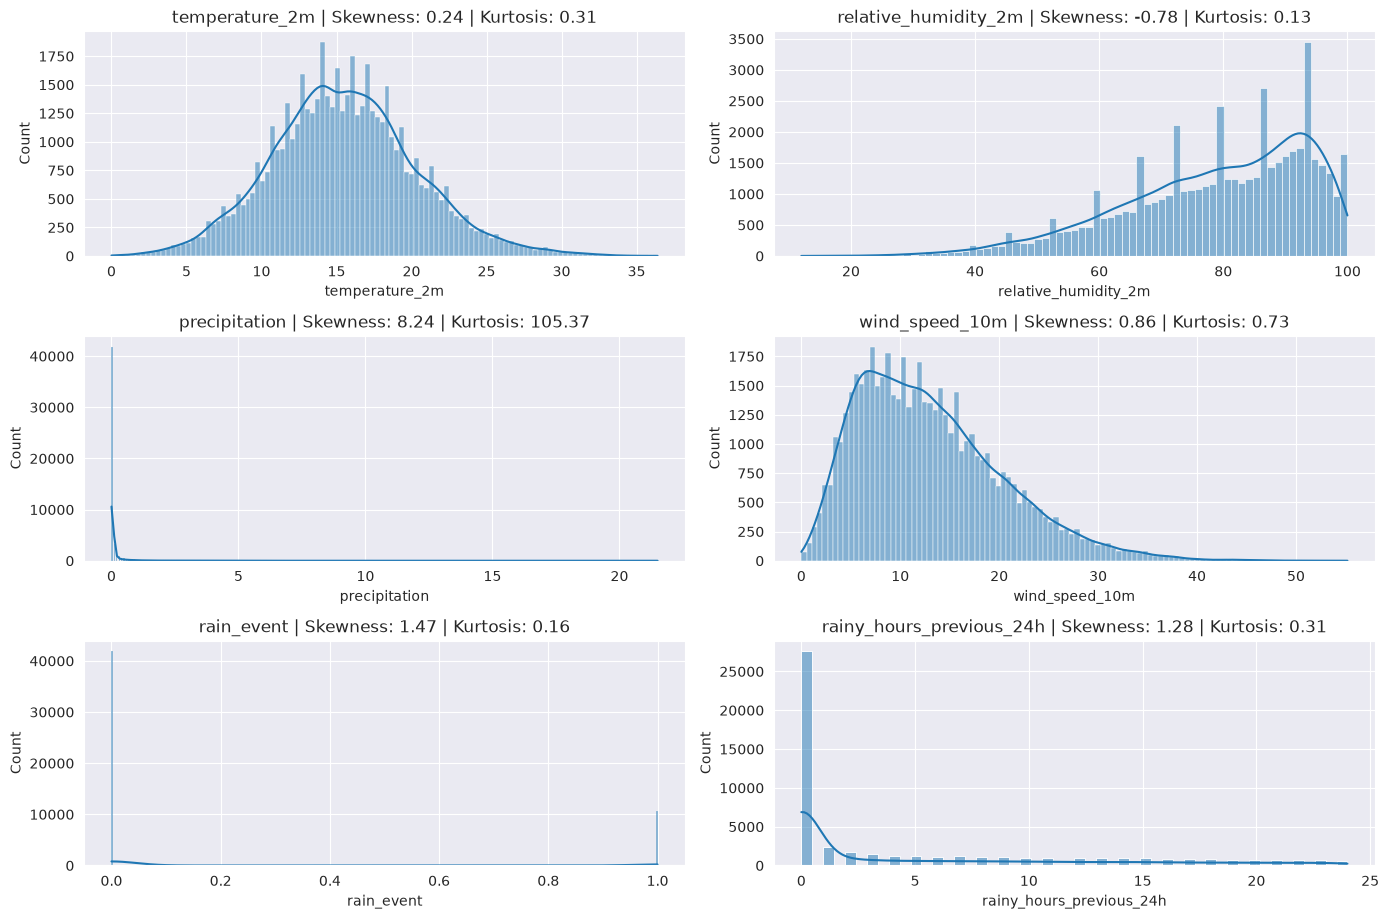

In [22]:
# Plot the weather variables distribution

numerical_columns = df_porto.select_dtypes(include=["int64", "float64"]).columns

plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 2, idx)
    sns.histplot(df_porto[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df_porto[feature].skew(), 2)} | Kurtosis: {round(df_porto[feature].kurtosis(), 2)}")

plt.tight_layout()
plt.show()

Calculate $\Pr(H_t \geq 50\% \mid y_t=1)$:

In [16]:
rainy = df_porto[df_porto["rain_event"] == 1]
print((rainy["relative_humidity_2m"] >= 50).mean())

0.9988813274913769


# Comparative Data Analysis

In [19]:
config, df_lisboa, df_porto = get_fresh_dataframes_and_config()

Calculate $\mathrm{std}(R_m)$:

In [29]:
print(f"Lisboa: {df_lisboa.set_index("time")["rain_event"].resample("MS").mean().mul(100).std():.1f}")
print(f"Porto: {df_porto.set_index("time")["rain_event"].resample("MS").mean().mul(100).std():.1f}")

Lisboa: 9.3
Porto: 12.7


Calculate $\mathbb{E}\left[C^{(24)}_t \mid C^{(24)}_t > 0\right]$:

In [30]:
df_lisboa["rainy_hours_previous_24h"] = df_lisboa["rain_event"].shift(1).rolling(window=24, min_periods=24).sum()
df_porto["rainy_hours_previous_24h"] = df_porto["rain_event"].shift(1).rolling(window=24, min_periods=24).sum()

print(f"Lisboa: {df_lisboa.loc[df_lisboa["rainy_hours_previous_24h"] > 0, "rainy_hours_previous_24h"].mean():.1f}")
print(f"Porto: {df_porto.loc[df_porto["rainy_hours_previous_24h"] > 0, "rainy_hours_previous_24h"].mean():.1f}")

Lisboa: 7.1
Porto: 10.3


Calculate $\mathrm{median}\left((B_i)_{i=1}^b \right)$ and $\mathrm{median}\left((D_i)_{i=1}^d \right)$:

In [ ]:
def calculate_rainy_and_dry_period_median(df: pd.DataFrame) -> tuple[int, int]:
    # Creates a new group whenever rain_event changes:
    # rain_event:  0 0 0 1 1 0 1 1 1
    # group_id:    1 1 1 2 2 3 4 4 4
    group_id = (
        df["rain_event"]
        .ne(df["rain_event"].shift())
        .cumsum()
    )

    periods = (
        df.groupby(group_id)["rain_event"]
        .agg(
            event_type="first",
            duration="size"
        )
    )

    rainy_period_lengths = periods.loc[periods["event_type"] == 1, "duration"]
    dry_period_lengths = periods.loc[periods["event_type"] == 0, "duration"]

    return rainy_period_lengths.median(), dry_period_lengths.median()

lisboa_rain_median, lisboa_dry_median = calculate_rainy_and_dry_period_median(df_lisboa)
porto_rain_median, porto_dry_median = calculate_rainy_and_dry_period_median(df_porto)

print(f"Lisboa median rainy period: {lisboa_rain_median}")
print(f"Lisboa median dry period: {lisboa_dry_median}")

print(f"Porto median rainy period: {porto_rain_median}")
print(f"Porto median dry period: {porto_dry_median}")

Lisboa median rainy period: 2.0
Lisboa median dry period: 4.0
Porto median rainy period: 3.0
Porto median dry period: 3.0


# Data Stream Mining Experiment

In [2]:
config, df_lisboa, df_porto = get_fresh_dataframes_and_config()

# Prepare the data streams
lisboa_stream = prepare_city_stream(config["preprocessing"], df_lisboa)
porto_stream = prepare_city_stream(config["preprocessing"], df_porto)
streams = {"Lisboa": lisboa_stream, "Porto": porto_stream}

# Run the experiment and save the results
results = ExperimentResults(config)
results.run(streams)
results.save(out_dir="results")

print(results.summary)

Lisboa / A / gaussian_naive_bayes: Accuracy=0.921, Macro-F1=0.751, Precision=0.848, Recall=0.402
Lisboa / A / online_logistic_regression: Accuracy=0.925, Macro-F1=0.774, Precision=0.831, Recall=0.457
Lisboa / A / hoeffding_tree: Accuracy=0.934, Macro-F1=0.836, Precision=0.744, Recall=0.678
Lisboa / A / online_bagging: Accuracy=0.935, Macro-F1=0.842, Precision=0.731, Recall=0.710
Lisboa / A / adaptive_random_forest: Accuracy=0.926, Macro-F1=0.799, Precision=0.751, Recall=0.557
Lisboa / B / gaussian_naive_bayes: Accuracy=0.915, Macro-F1=0.771, Precision=0.694, Recall=0.512
Lisboa / B / online_logistic_regression: Accuracy=0.927, Macro-F1=0.793, Precision=0.793, Recall=0.517
Lisboa / B / hoeffding_tree: Accuracy=0.932, Macro-F1=0.838, Precision=0.717, Recall=0.710
Lisboa / B / online_bagging: Accuracy=0.935, Macro-F1=0.841, Precision=0.731, Recall=0.709
Lisboa / B / adaptive_random_forest: Accuracy=0.922, Macro-F1=0.790, Precision=0.731, Recall=0.543
Porto / A / gaussian_naive_bayes: Accu

In [5]:
window_size = results.config['evaluation']['window_size']
warmup_fraction = results.config['evaluation']['warmup_fraction']

dips = results.history.loc[
    (results.history['representation'] == 'A')
    & (results.history['window_macro_f1'] == 0.5)
    & (results.history['window_accuracy'] == 1.0)
    & (results.history['n_evaluated'] >= window_size)
].copy()

records = []

for row in dips.itertuples():
    stream = streams[row.city]

    warmup_rows = int(len(stream['y']) * warmup_fraction)

    # Reconstruct the exact 720-observation evaluation window
    end = warmup_rows + int(row.n_evaluated)
    start = end - window_size

    window = stream['y'].iloc[start:end]

    records.append({
        'city': row.city,
        'model': row.model,
        'window_start': stream['timestamp'].iloc[start],
        'window_end': stream['timestamp'].iloc[end - 1],
        'window_macro_f1': row.window_macro_f1,
        'window_accuracy': row.window_accuracy,
        'actual_rain_hours': int(window.sum()),
        'actual_dry_hours': int((window == 0).sum()),
    })

inspection = pd.DataFrame(records)

display(inspection)

""


In [6]:
window_size = results.config['evaluation']['window_size']

models = ['online_bagging', 'hoeffding_tree']

predictions = results.predictions.loc[
    (results.predictions['representation'] == 'A')
    & (results.predictions['model'].isin(models))
].copy()

predictions['timestamp'] = pd.to_datetime(predictions['timestamp'])

predictions = predictions.sort_values(
    ['city', 'representation', 'model', 'timestamp']
)

groups = predictions.groupby(['city', 'representation', 'model'])

for col in ['y_true', 'y_pred']:
    predictions[f'window_{col}'] = groups[col].transform(
        lambda x: x.rolling(window_size, min_periods=window_size).sum()
    )

# Select windows where Macro-F1 is near 50%
dips = results.history.loc[
    (results.history['representation'] == 'A')
    & (results.history['model'].isin(models))
    & (results.history['window_macro_f1'].between(0.49, 0.55))
].copy()

dips['timestamp'] = pd.to_datetime(dips['timestamp'])

inspection = dips.merge(
    predictions[[
        'city', 'representation', 'model', 'timestamp',
        'window_y_true', 'window_y_pred'
    ]],
    on=['city', 'representation', 'model', 'timestamp'],
    how='left'
)

display(inspection[[
    'city', 'model', 'timestamp',
    'window_macro_f1', 'window_accuracy',
    'window_y_true', 'window_y_pred'
]])

,city,model,timestamp,window_macro_f1,window_accuracy,window_y_true,window_y_pred
0,Lisboa,hoeffding_tree,2021-08-05 17:00:00,0.499305,0.997222,1.0,1.0
1,Lisboa,hoeffding_tree,2021-08-06 17:00:00,0.499305,0.997222,1.0,1.0
2,Lisboa,hoeffding_tree,2021-08-07 17:00:00,0.498607,0.994444,2.0,2.0
3,Lisboa,hoeffding_tree,2021-08-08 17:00:00,0.498607,0.994444,2.0,2.0
4,Lisboa,hoeffding_tree,2021-08-09 17:00:00,0.498607,0.994444,2.0,2.0
...,...,...,...,...,...,...,...
101,Lisboa,online_bagging,2023-08-31 17:00:00,0.497558,0.990278,4.0,3.0
102,Lisboa,online_bagging,2023-09-01 17:00:00,0.498258,0.993056,3.0,2.0
103,Lisboa,online_bagging,2023-09-02 17:00:00,0.496855,0.987500,5.0,4.0
104,Porto,hoeffding_tree,2021-09-06 17:00:00,0.499305,0.997222,1.0,1.0


In [3]:
print_latex_results_tables(results.summary)

\begin{table}[htbp]
    \centering
    \caption
    {
        Predictive and computational performance for Representation A.
        Predictive metrics are reported as percentages.
        Each cell reports
        \colorbox{LisboaGreen!70}{\scriptsize Lisboa}
        in the top-left triangle and
        \colorbox{PortoRed!70}{\scriptsize Porto}
        in the bottom-right triangle.
    }
    \label{tab:representation-a-results}

    \resizebox{\textwidth}{!}{%
        \begin{tabularx}{0.98\textwidth}{@{}Y C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm}@{}}
            \toprule
            \textbf{Model}
            & \textbf{Acc.}
            & \textbf{Macro-F1}
            & \textbf{Prec.}
            & \textbf{Recall}
            & \textbf{Pred. ms/event}
            & \textbf{Update ms/event} \\
            \midrule
            GaussianNB & \splitcell{92.1}{89.2} & \splitcell{75.1}{79.4} & \splitcell{84.8}{90.8} & \splitcell{40.2}{50.8} & \splitcell{0.052}{0.052} & \spl

'\\begin{table}[htbp]\n    \\centering\n    \\caption\n    {\n        Predictive and computational performance for Representation A.\n        Predictive metrics are reported as percentages.\n        Each cell reports\n        \\colorbox{LisboaGreen!70}{\\scriptsize Lisboa}\n        in the top-left triangle and\n        \\colorbox{PortoRed!70}{\\scriptsize Porto}\n        in the bottom-right triangle.\n    }\n    \\label{tab:representation-a-results}\n\n    \\resizebox{\\textwidth}{!}{%\n        \\begin{tabularx}{0.98\\textwidth}{@{}Y C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm} C{1.55cm}@{}}\n            \\toprule\n            \\textbf{Model}\n            & \\textbf{Acc.}\n            & \\textbf{Macro-F1}\n            & \\textbf{Prec.}\n            & \\textbf{Recall}\n            & \\textbf{Pred. ms/event}\n            & \\textbf{Update ms/event} \\\\\n            \\midrule\n            GaussianNB & \\splitcell{92.1}{89.2} & \\splitcell{75.1}{79.4} & \\splitcell{84.8}{90.8} & \\sp

# Report Figures Creation

In [3]:
from src.plotting import plot_R_m, plot_C_24, plot_city_comparison, plot_model_performance_over_time

plotting_config = config["plotting"]

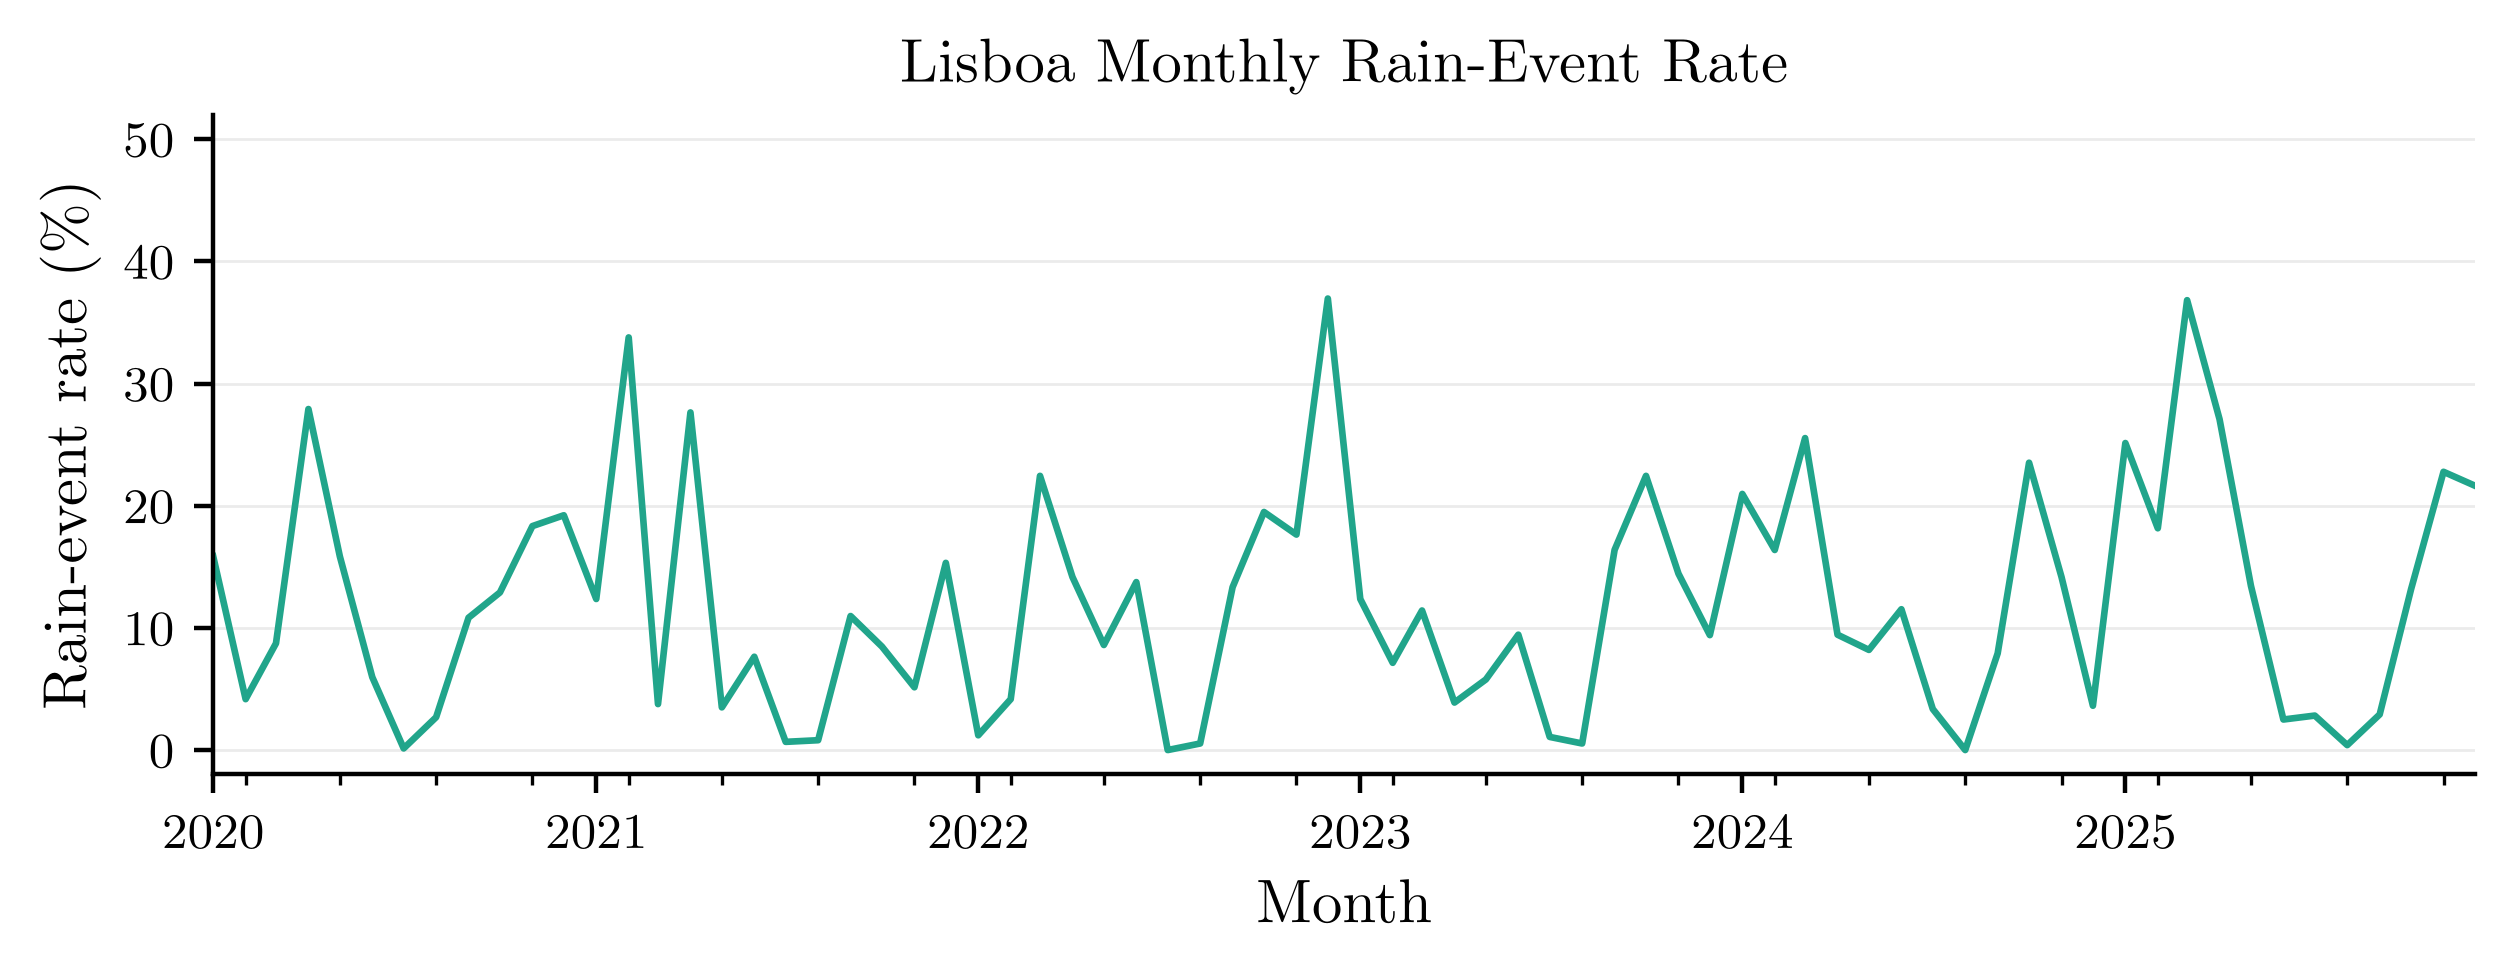

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Lisboa_R_m_rg45yes4.pdf


In [4]:
plot_R_m(plotting_config, df_cleaned_lisboa, "Lisboa")

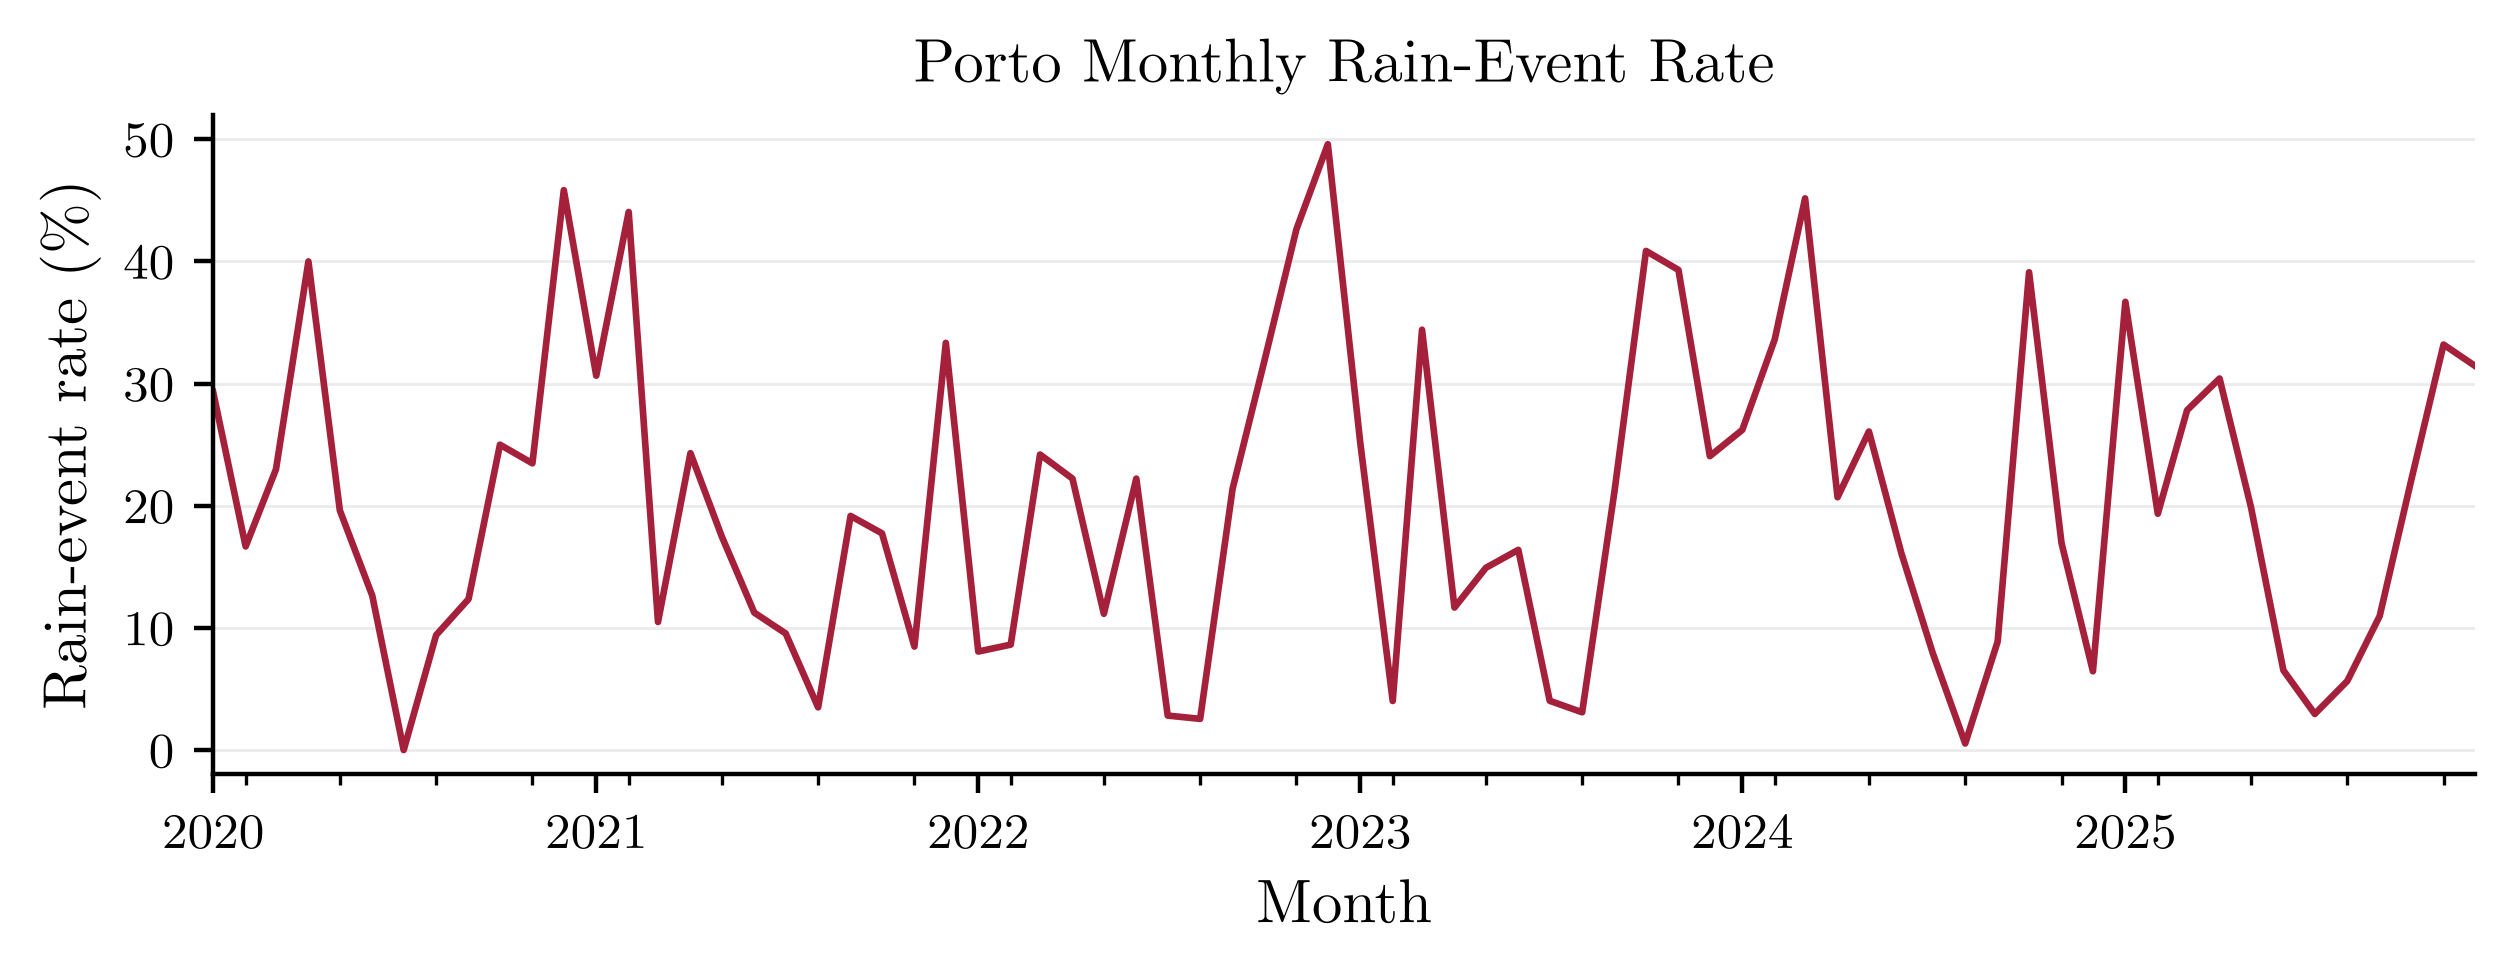

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Porto_R_m_crgkblzs.pdf


In [5]:
plot_R_m(plotting_config, df_cleaned_porto, "Porto")

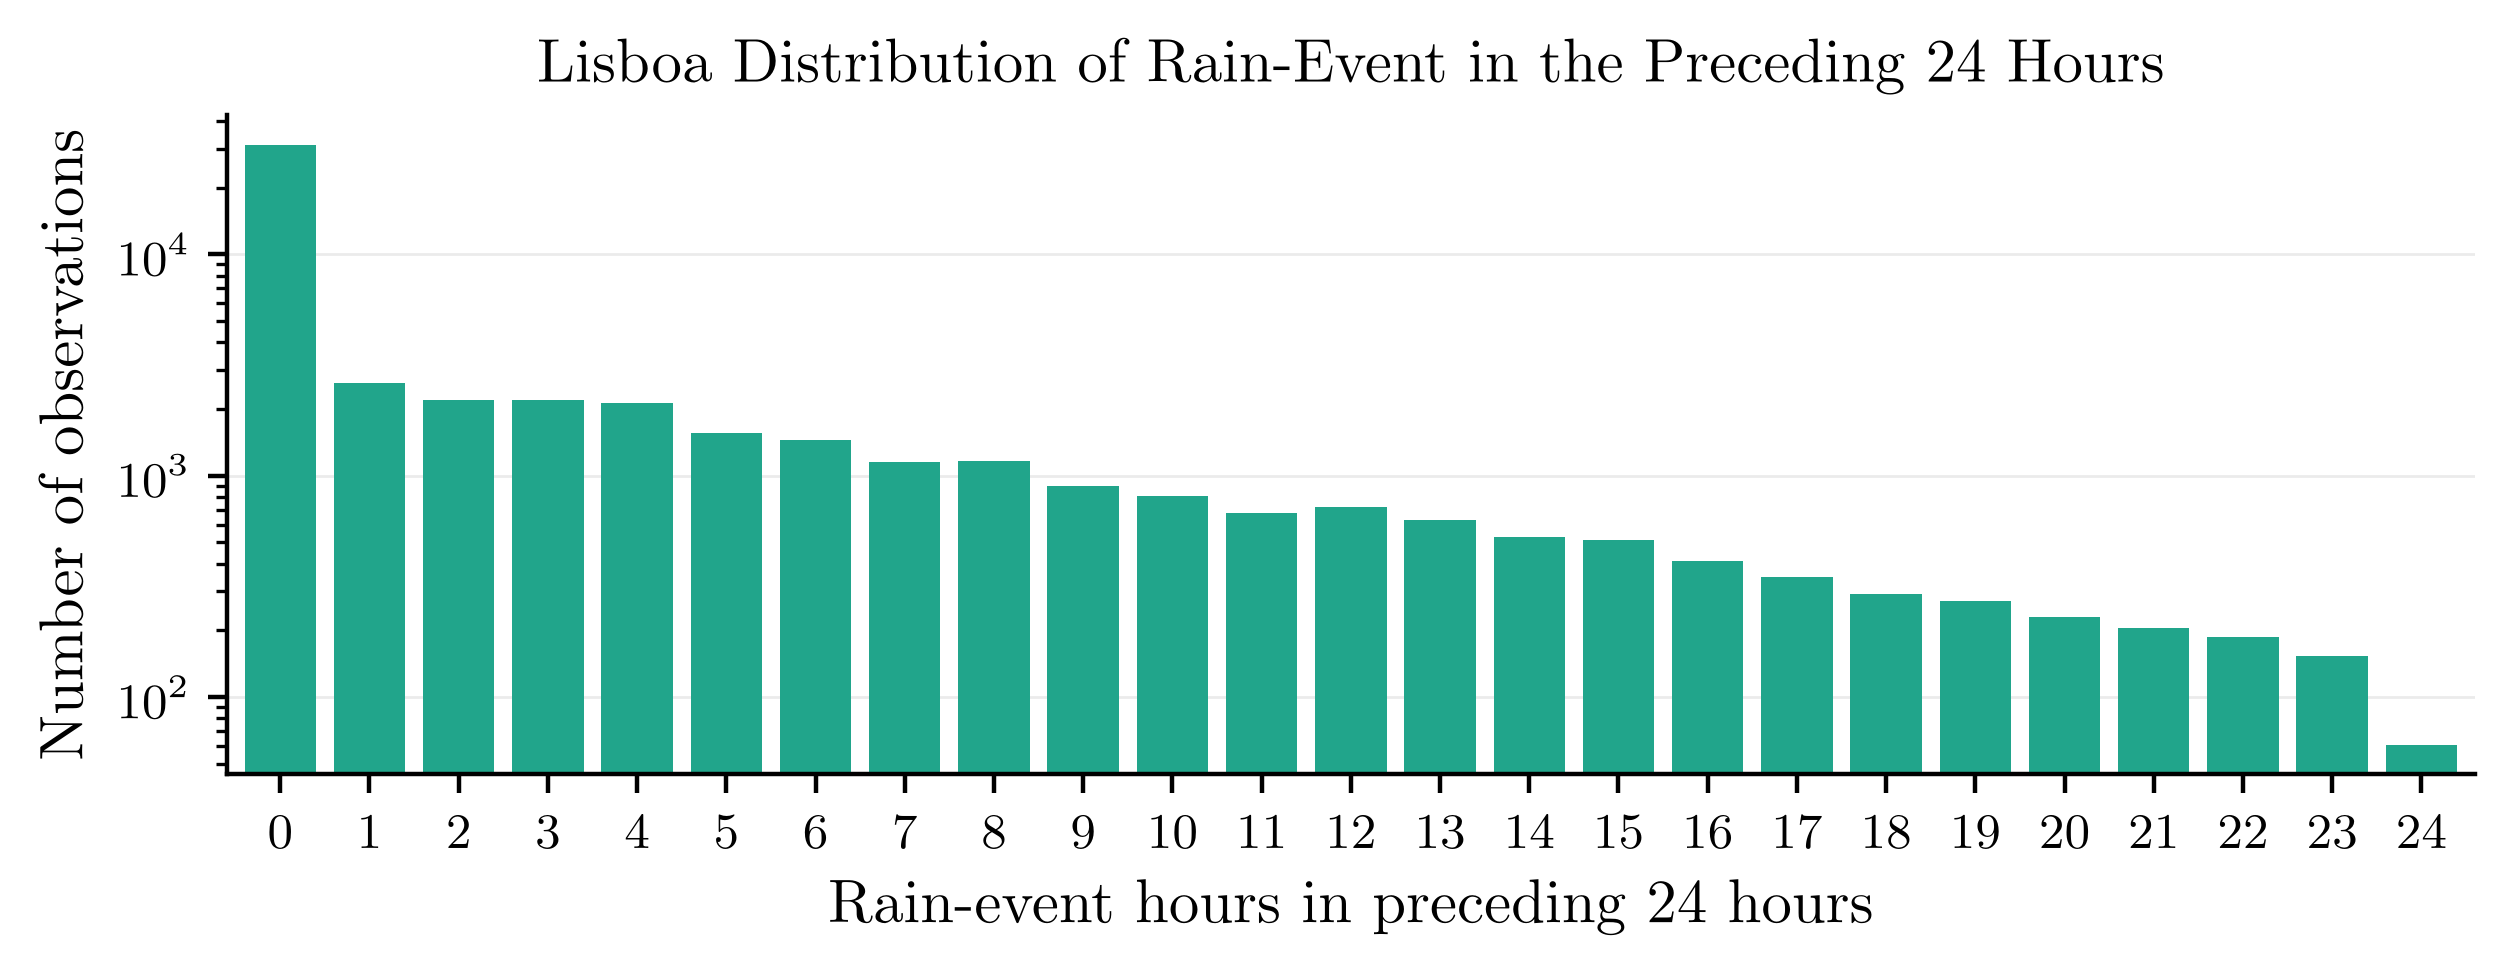

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Lisboa_C_24_ct4h8v72.pdf


In [6]:
plot_C_24(plotting_config, df_cleaned_lisboa, "Lisboa")

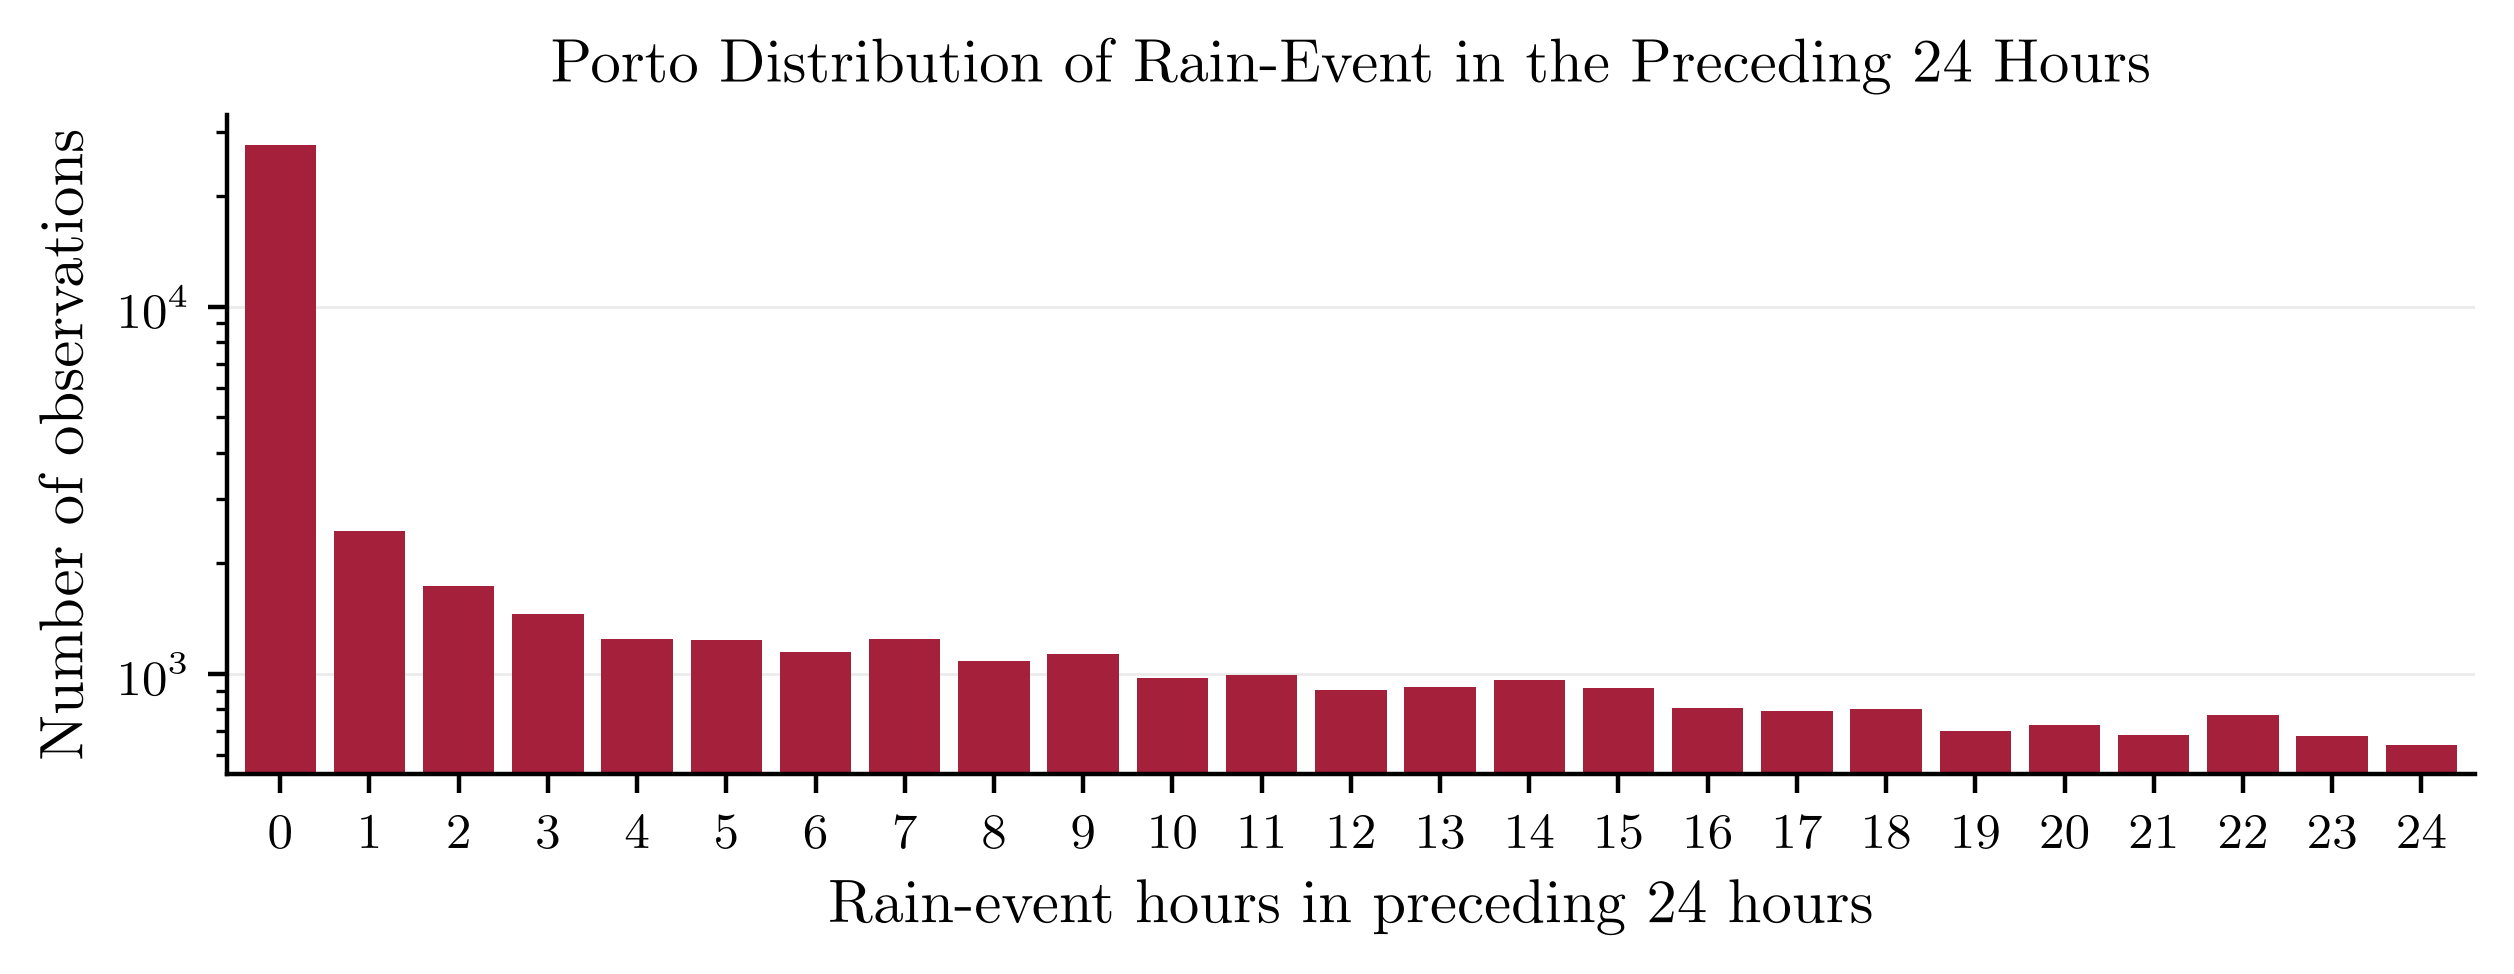

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Porto_C_24_4gzizosq.pdf


In [7]:
plot_C_24(plotting_config, df_cleaned_porto, "Porto")

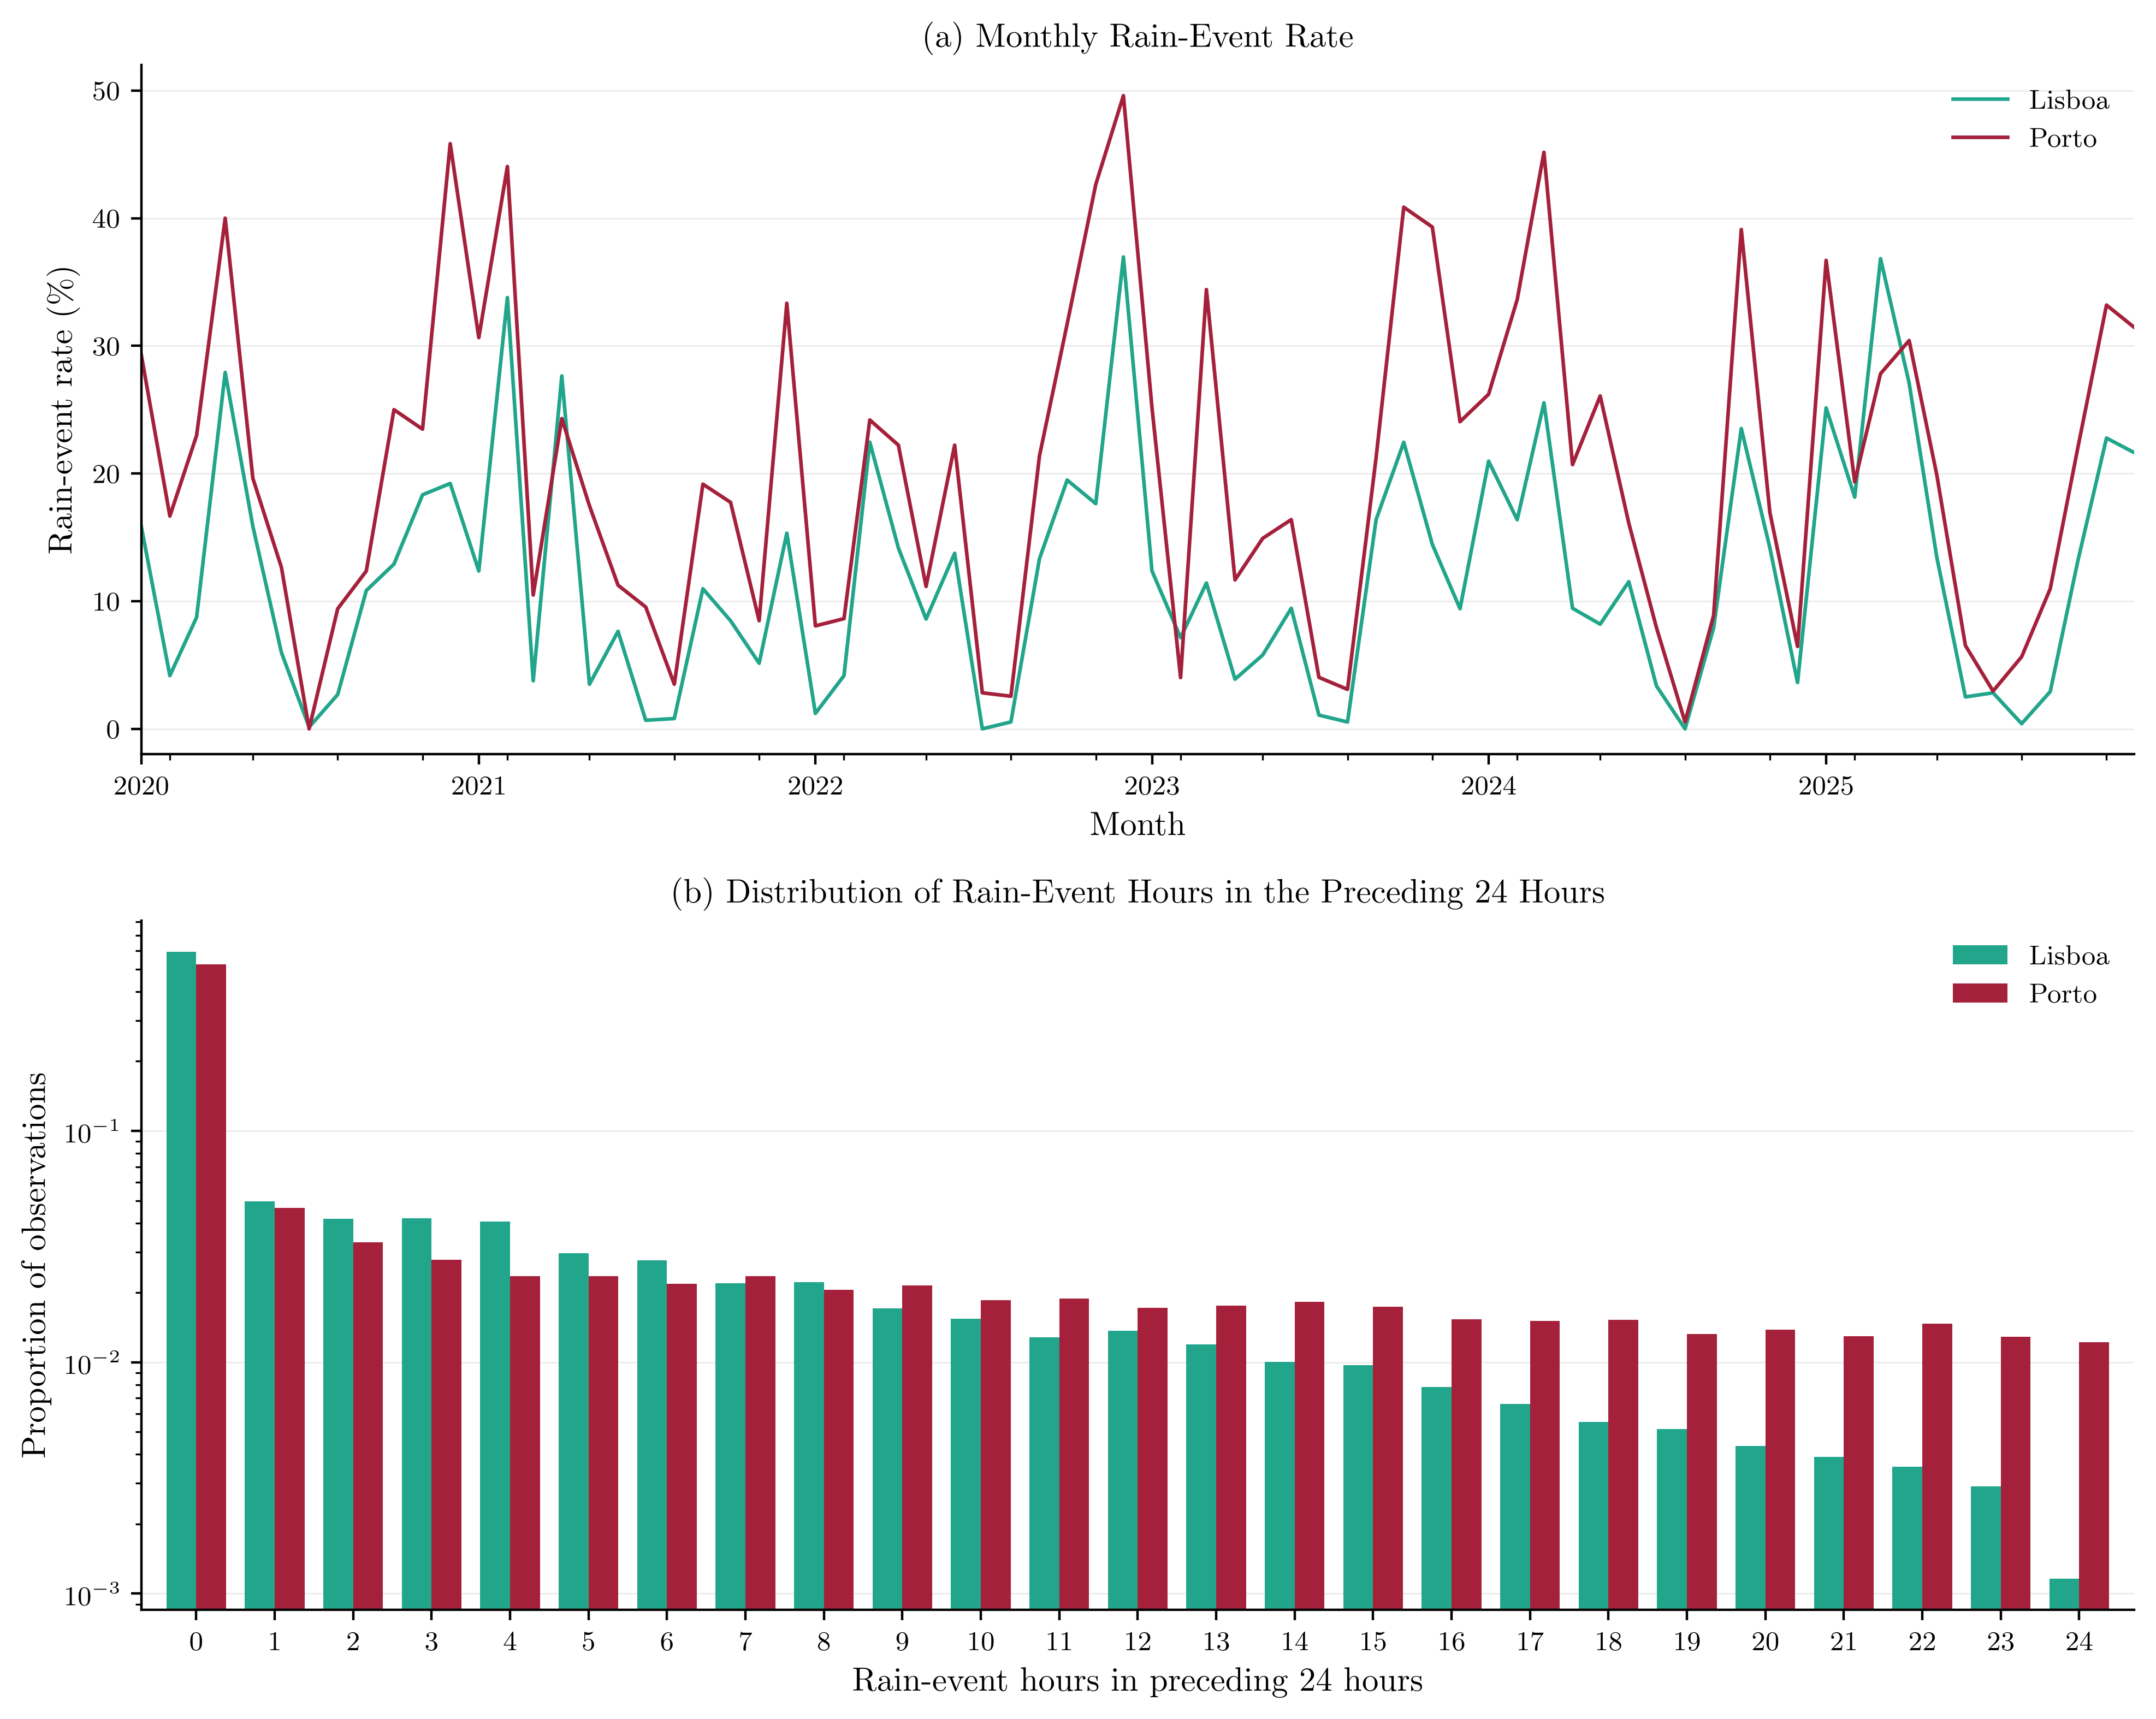

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\city_comparison_swjy43ai.pdf


In [8]:
plot_city_comparison(plotting_config, df_cleaned_lisboa, df_cleaned_porto)

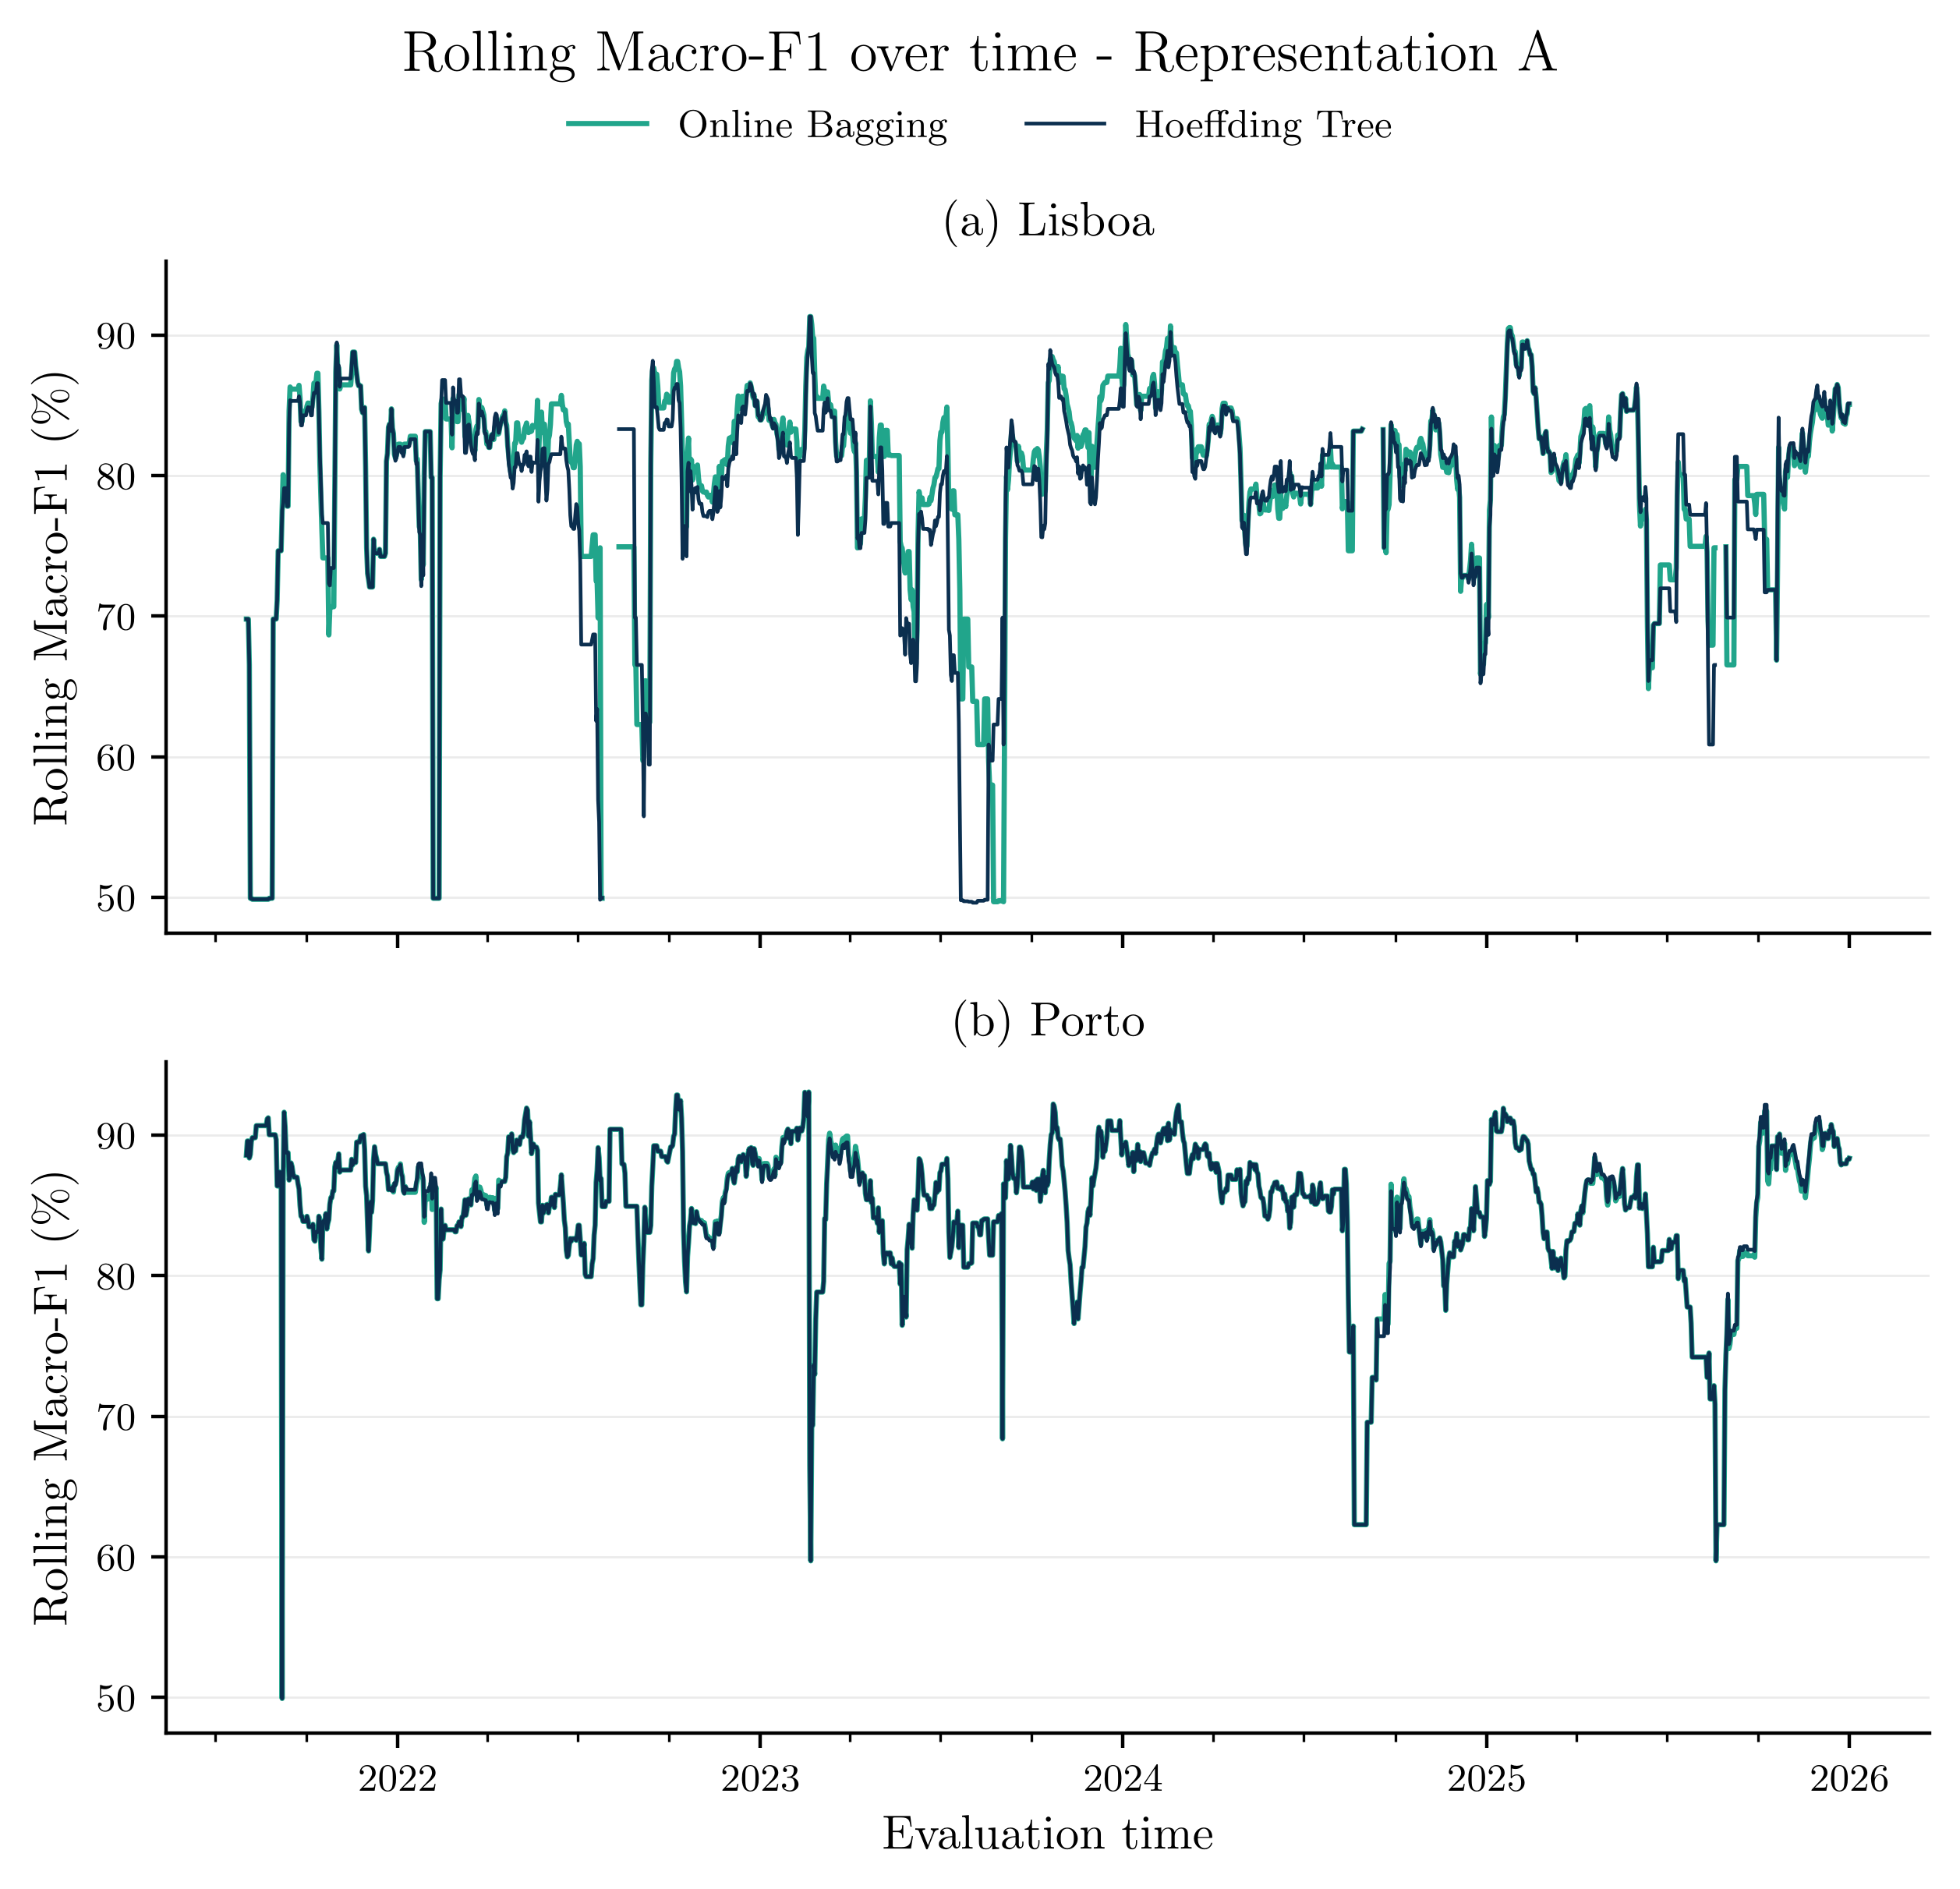

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\model_performance_over_time_ml4yi9fm.pdf


In [4]:
# Make sure to run the Data Stream Mining Experiment before running this cell, 
# because it uses the results object created by the experiment
plot_model_performance_over_time(plotting_config, results, representation="A")